In [1]:
from transformers import AutoModel, AutoTokenizer

model = AutoModel.from_pretrained("klue/bert-base")
tokenizer = AutoTokenizer.from_pretrained("klue/bert-base")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: klue/bert-base
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [7]:
inputs = tokenizer(
  ["안녕하세요 저는 허완입니다.",
   "저는 여러가지 모델을 공부중입니다."], 
   return_tensors="pt",
   padding=True, truncation=True)

inputs

{'input_ids': tensor([[    2,  5891,  2205,  5971,  1535,  2259,  1905,  2365, 12190,    18,
             3,     0],
        [    2,  1535,  2259,  3789,  4314,  4347,  2069,  4244,  2284, 12190,
            18,     3]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])}

In [19]:
for idx, token in zip(
  tokenizer.all_special_ids,
  tokenizer.all_special_tokens
):
  print(f"{idx}: {token}")

1: [UNK]
3: [SEP]
0: [PAD]
2: [CLS]
4: [MASK]


In [25]:
for seq in inputs["input_ids"].tolist():
  sentence = []
  for idx in seq:
    if True:#tokenizer.convert_ids_to_tokens(idx) != "[PAD]":
      sentence.append(tokenizer.convert_ids_to_tokens(idx))
  print(seq)
  print(" ".join(sentence))
  print()
    

[2, 5891, 2205, 5971, 1535, 2259, 1905, 2365, 12190, 18, 3, 0]
[CLS] 안녕 ##하 ##세요 저 ##는 허 ##완 ##입니다 . [SEP] [PAD]

[2, 1535, 2259, 3789, 4314, 4347, 2069, 4244, 2284, 12190, 18, 3]
[CLS] 저 ##는 여러 ##가지 모델 ##을 공부 ##중 ##입니다 . [SEP]



In [8]:
import torch 
model.eval()

with torch.no_grad():
  outputs = model(
    input_ids=inputs["input_ids"],
    attention_mask=inputs["attention_mask"],
    token_type_ids=inputs["token_type_ids"],
  )

model.train()

type(outputs["pooler_output"]), outputs["pooler_output"].shape if isinstance(outputs["pooler_output"], torch.Tensor) else None

(torch.Tensor, torch.Size([2, 768]))

In [14]:
for k in outputs.keys():
  print(k)
  print(outputs[k].shape)

last_hidden_state
torch.Size([2, 12, 768])
pooler_output
torch.Size([2, 768])


In [28]:
model.config.hidden_size, model.config.vocab_size

(768, 32000)

In [29]:
tokenizer.convert_ids_to_tokens(torch.tensor([11, 12, 13]))

["'", '(', ')']

In [30]:
torch.tensor([11, 12, 13]).argmax(dim=-1)

tensor(2)

In [37]:
from torch.nn import Module
import torch.nn as nn

# 시퀀스를 보고 다음 단어를 출력하게 하기
class MyModel(Module):

  def __init__(
      self,
      model_name="klue/bert-base"
  ):
    super().__init__()

    self.model = AutoModel.from_pretrained(model_name)
    self.tokenizer = AutoTokenizer.from_pretrained(model_name)

    self.fc_next_token = nn.Linear(
      model.config.hidden_size,
      model.config.vocab_size
    )

    self.softmax = nn.Softmax(dim=-1)


  def forward(self, seq: list[str]):
    inputs = self.tokenizer(
      seq,
      padding=True,
      truncation=True,
      return_tensors="pt"
    )

    for k in inputs.keys():
      print(f"{k}: {inputs[k].shape if isinstance(inputs[k], torch.Tensor) else type(inputs[k])}")

    outputs = model(**inputs)

    if not hasattr(outputs, "pooler_output"):
      raise Exception("outputs don't have attr 'pooler_output'")
    
    pooler = outputs["pooler_output"] 

    pred = self.fc_next_token(pooler)
    # pred_scaled = self.softmax(pred)

    return self.tokenizer.convert_ids_to_tokens(pred.argmax(dim=-1).tolist())

my_model = MyModel()


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: klue/bert-base
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [44]:
my_model.eval()

with torch.no_grad():
  print(my_model("나는 오늘 [MASK]에 갔다."))

input_ids: torch.Size([1, 9])
token_type_ids: torch.Size([1, 9])
attention_mask: torch.Size([1, 9])
['태수']


In [55]:
class MySentiment(Module):
  def __init__(self, model_name="klue/bert-base", num_classes=1):
    super().__init__()
    self.model = AutoModel.from_pretrained(model_name)
    self.tokenizer = AutoTokenizer.from_pretrained(model_name)

    self.classifier = nn.Linear(self.model.config.hidden_size, num_classes)

  def forward(self, sentence: list[str] | str):
    if isinstance(sentence, str):
      sentence = [sentence]

    inputs = self.tokenizer(
      sentence,
      padding=True,
      truncation=True,
      return_tensors="pt"
    )

    inputs = {
      k: v.to(self.model.device)
      for k, v
      in inputs.items()
    }

    outputs = self.model(**inputs)

    if not hasattr(outputs, "pooler_output"):
      raise Exception(f"outputs doesn't have attr 'pooler_output'\noutputs type: {type(outputs)}")

    return self.classifier(outputs["pooler_output"])

In [48]:
from datasets import load_dataset

dataset = load_dataset(
  "csv",
  data_files={
    "train": "https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt",
    "test": "https://raw.githubusercontent.com/e9t/nsmc/master/ratings_test.txt"
  },
  delimiter="\t"
)

dataset

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'document', 'label'],
        num_rows: 150000
    })
    test: Dataset({
        features: ['id', 'document', 'label'],
        num_rows: 50000
    })
})

In [60]:
len(dataset["train"]["label"])

150000

In [ ]:
dataset["train"]["document"][:10]

In [61]:
from torch.utils.data import Dataset

class MyDataset(Dataset):
  def __init__(self, data):
    super().__init__()

    self.label = data["label"]
    self.document = data["document"]

  def __len__(self):
    return len(self.label)

  def __getitem__(self, idx):
    return self.document[idx], self.label[idx]


In [106]:
from torch.utils.data import random_split

train_dataset, val_dataset = random_split(
  MyDataset(dataset["train"].filter(
    lambda x: isinstance(x["document"], str)
    and bool(x["document"].strip())
  )),
  [0.8, 0.2]
)
test_dataset = MyDataset(dataset["test"].filter(
    lambda x: isinstance(x["document"], str)
    and bool(x["document"].strip())
  ))


Filter:   0%|          | 0/150000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/50000 [00:00<?, ? examples/s]

In [107]:
DEVICE = torch.device(
  "cuda" if torch.cuda.is_available() else "cpu"
)

In [108]:
from torch.utils.data import DataLoader

def collate_fn(batch):
  sentences = []
  labels = []

  for sentence, label in batch:
    sentences.append(sentence)
    labels.append(label)

  return sentences, torch.tensor(labels, dtype=torch.float32)

loader = { 
  "train": DataLoader(
    train_dataset,
    shuffle=True,
    batch_size=128,
    collate_fn=collate_fn
  ),
  "val": DataLoader(
    val_dataset,
    shuffle=False,
    batch_size=128,
    collate_fn=collate_fn
  ),
  "test": DataLoader(
    test_dataset,
    shuffle=False,
    batch_size=128,
    collate_fn=collate_fn
  )
}

In [109]:
model = MySentiment()

model("hello world!")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: klue/bert-base
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tensor([[0.0673]], grad_fn=<AddmmBackward0>)

In [160]:
from contextlib import nullcontext
import tqdm

def run_epoch(model, loader, criterion, optimizer=None, scheduler=None, scaler=None):
  device = next(model.parameters()).device
  is_training = optimizer is not None
  model.eval() if not is_training else model.train()

  total_loss = 0
  total_acc = 0
  total_size = 0

  for documents, labels in tqdm.tqdm(loader, "epoch"):
    labels = labels.to(device)

    with torch.set_grad_enabled(is_training):
      with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device.type=="cuda")):
        # [B, 1]
        logits = model(documents)

        loss = criterion(logits, labels.unsqueeze(-1))

      if is_training:
        optimizer.zero_grad()
        if scaler is not None:
          scaler.scale(loss).backward()

          old_scale = scaler.get_scale()
          scaler.step(optimizer)
          scaler.update()
          stepped = scaler.get_scale() >= old_scale
        else:
          loss.backward()
          optimizer.step()
          stepped=True

        if scheduler is not None and stepped:
          scheduler.step()

      batch_size = len(labels)
      total_size += batch_size
      total_loss += loss.item() * batch_size
      total_acc += (
        (logits > 0.0).reshape(-1).float() == labels
      ).sum().item()
      # print("total_acc:", total_acc)

  return total_loss / total_size, total_acc / total_size
      

In [128]:
from transformers import get_linear_schedule_with_warmup

model = MySentiment()
model = model.to(DEVICE)

model.model.requires_grad_(True)#False)
optimizer = torch.optim.AdamW(
  model.parameters(),
  # filter(lambda p: p.requires_grad, model.parameters()), 
  # lr=1e-3, 
  lr=2e-5, 
  betas=(0.9, 0.99), 
  weight_decay=0.01
)

total_steps = len(loader["train"]) * EPOCHS

scheduler = get_linear_schedule_with_warmup(
  optimizer,
  num_warmup_steps=int(total_steps * 0.1),
  num_training_steps=total_steps
)

criterion = torch.nn.BCEWithLogitsLoss()

scaler = torch.amp.GradScaler(
  "cuda",
  enabled=(model.model.device.type=="cuda")
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: klue/bert-base
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [130]:
torch.save({
  "best_val_loss": best_val_loss,
  "best_val_loss_epoch": best_val_loss_epoch,
  "best_state_dict": best_state_dict,
  "history": history
}, SAVE_DIR)

In [ ]:
from pathlib import Path
import copy

SAVE_DIR = Path("bert-sentiment-classification-backbone-not-freezed.pth")

EPOCHS=10

# best_val_loss = float("inf")
# best_val_loss_epoch = 0
# best_state_dict = None

# history = {
#   "train": {
#     "loss": [],
#     "acc": []
#   },
#   "val": {
#     "loss": [],
#     "acc": []
#   }
# }

for epoch in range(1, EPOCHS+1):
  train_loss, train_acc = run_epoch(model, loader["train"], criterion, optimizer, scheduler, scaler)
  val_loss, val_acc = run_epoch(model, loader["val"], criterion)

  print(f"epoch-{epoch} | train_loss: {train_loss} | train_acc: {train_acc} | val_loss: {val_loss} | val_acc: {val_acc} ")
  
  history["train"]["loss"].append(train_loss)
  history["train"]["acc"].append(train_acc)
  history["val"]["loss"].append(val_loss)
  history["val"]["acc"].append(val_acc)

  if val_loss < best_val_loss:
    best_state_dict = copy.deepcopy(model.state_dict())
    best_val_loss_epoch = epoch
    best_val_loss = val_loss

torch.save({
  "best_val_loss": best_val_loss,
  "best_val_loss_epoch": best_val_loss_epoch,
  "best_state_dict": best_state_dict,
  "history": history
}, SAVE_DIR)

epoch: 100%|██████████| 235/235 [00:46<00:00,  5.05it/s]


epoch-1 | train_loss: 0.3519477579639476 | train_acc: 64.34514483816127 | val_loss: 0.2577079780030487 | val_acc: 64.40244674822495 


epoch: 100%|██████████| 235/235 [00:44<00:00,  5.31it/s]


epoch-2 | train_loss: 0.23392072254516486 | train_acc: 64.40049668322277 | val_loss: 0.23419384392640077 | val_acc: 64.42814760492017 


epoch: 100%|██████████| 235/235 [00:46<00:00,  5.05it/s]


...

epoch-6 | train_loss: 0.06659655176751834 | train_acc: 64.46451548384947 | val_loss: 0.3588739601044763 | val_acc: 64.41898063268776 


epoch: 100%|██████████| 235/235 [00:46<00:00,  5.04it/s]


epoch-7 | train_loss: 0.051090455476841976 | train_acc: 64.44306476882562 | val_loss: 0.38641985294041925 | val_acc: 64.40674689156305 


epoch:   0%|          | 4/938 [00:05<20:41,  1.33s/it]


KeyboardInterrupt: 

In [161]:
from pathlib import Path
import copy

SAVE_DIR = Path("bert-sentiment-classification-backbone-not-freezed.pth")

EPOCHS=10

# best_val_loss = float("inf")
# best_val_loss_epoch = 0
# best_state_dict = None

# history = {
#   "train": {
#     "loss": [],
#     "acc": []
#   },
#   "val": {
#     "loss": [],
#     "acc": []
#   }
# }

for epoch in range(7, EPOCHS+1):
  train_loss, train_acc = run_epoch(model, loader["train"], criterion, optimizer, scheduler, scaler)
  val_loss, val_acc = run_epoch(model, loader["val"], criterion)

  print(f"epoch-{epoch} | train_loss: {train_loss} | train_acc: {train_acc} | val_loss: {val_loss} | val_acc: {val_acc} ")
  
  history["train"]["loss"].append(train_loss)
  history["train"]["acc"].append(train_acc)
  history["val"]["loss"].append(val_loss)
  history["val"]["acc"].append(val_acc)

  if val_loss < best_val_loss:
    best_state_dict = copy.deepcopy(model.state_dict())
    best_val_loss_epoch = epoch
    best_val_loss = val_loss

torch.save({
  "best_val_loss": best_val_loss,
  "best_val_loss_epoch": best_val_loss_epoch,
  "best_state_dict": best_state_dict,
  "history": history
}, SAVE_DIR)

epoch: 100%|██████████| 235/235 [00:33<00:00,  6.97it/s]


epoch-7 | train_loss: 0.03950763851313663 | train_acc: 0.9859995333177772 | val_loss: 0.429751323504807 | val_acc: 0.9032301076702557 


epoch: 100%|██████████| 235/235 [00:35<00:00,  6.69it/s]


epoch-8 | train_loss: 0.0333741123799949 | train_acc: 0.9880662688756292 | val_loss: 0.442515726590511 | val_acc: 0.9037634587819594 


epoch:  12%|█▏        | 116/938 [01:15<08:52,  1.54it/s]


KeyboardInterrupt: 

In [162]:
torch.save({
  "best_val_loss": best_val_loss,
  "best_val_loss_epoch": best_val_loss_epoch,
  "best_state_dict": best_state_dict,
  "history": history
}, SAVE_DIR)

In [ ]:
for idx, d in enumerate(dataset["train"]["document"]):
  if d is None: 
    print(idx)

25857
55737
110014
126782
140721


In [ ]:
dataset

DatasetDict({
    train: Dataset({
        features: ['id', 'document', 'label'],
        num_rows: 150000
    })
    test: Dataset({
        features: ['id', 'document', 'label'],
        num_rows: 50000
    })
})

In [ ]:
dataset["train"]["label"][140721]

0

In [163]:
state = torch.load(SAVE_DIR)
state["history"]

{'train': {'loss': [0.3519477579639476,
   0.23392072254516486,
   0.17384135279591,
   0.12593093332642216,
   0.09028349581700675,
   0.06659655176751834,
   0.051090455476841976,
   0.03950763851313663,
   0.0333741123799949],
  'acc': [64.34514483816127,
   64.40049668322277,
   64.43809793659788,
   64.38826294209807,
   64.44631487716258,
   64.46451548384947,
   64.44306476882562,
   0.9859995333177772,
   0.9880662688756292]},
 'val': {'loss': [0.2577079780030487,
   0.23419384392640077,
   0.23890106184227697,
   0.26693810074637303,
   0.30698629084763046,
   0.3588739601044763,
   0.38641985294041925,
   0.429751323504807,
   0.442515726590511],
  'acc': [64.40244674822495,
   64.42814760492017,
   64.42824760825361,
   64.41828060935364,
   64.4237807926931,
   64.41898063268776,
   64.40674689156305,
   0.9032301076702557,
   0.9037634587819594]}}

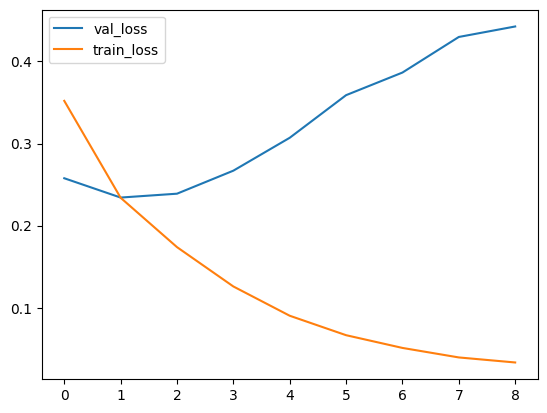

In [171]:
import matplotlib.pyplot as plt 
plt.plot(history["val"]["loss"], label="val_loss")
plt.plot(history["train"]["loss"], label="train_loss")
plt.legend()

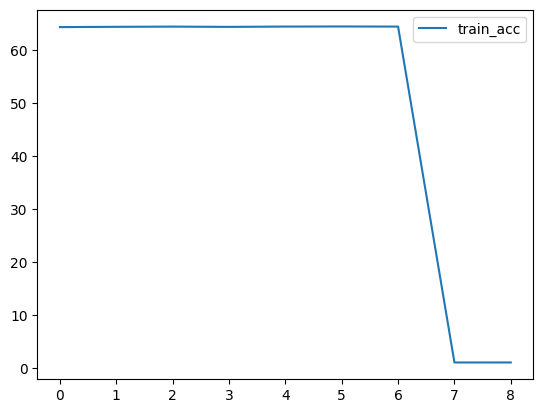

In [175]:
plt.plot(history["train"]["acc"], label="train_acc")
# plt.plot(history["val"]["acc"], label="val_acc")
plt.legend()

In [ ]:
sum([p.numel() for p in model.parameters()])

110618113

In [180]:
len(dataset["train"])

150000

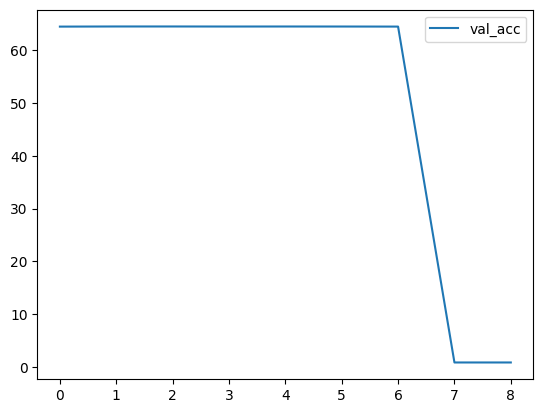

In [176]:
plt.plot(history["val"]["acc"], label="val_acc")
plt.legend()

In [154]:
counter = 0
for data in dataset["test"].to_iterable_dataset():
  counter += 1
  print(data)
  if counter > 10:
    break

{'id': 6270596, 'document': '굳 ㅋ', 'label': 1}
{'id': 9274899, 'document': 'GDNTOPCLASSINTHECLUB', 'label': 0}
{'id': 8544678, 'document': '뭐야 이 평점들은.... 나쁘진 않지만 10점 짜리는 더더욱 아니잖아', 'label': 0}
{'id': 6825595, 'document': '지루하지는 않은데 완전 막장임... 돈주고 보기에는....', 'label': 0}
{'id': 6723715, 'document': '3D만 아니었어도 별 다섯 개 줬을텐데.. 왜 3D로 나와서 제 심기를 불편하게 하죠??', 'label': 0}
{'id': 7898805, 'document': '음악이 주가 된, 최고의 음악영화', 'label': 1}
{'id': 6315043, 'document': '진정한 쓰레기', 'label': 0}
{'id': 6097171, 'document': '마치 미국애니에서 튀어나온듯한 창의력없는 로봇디자인부터가,고개를 젖게한다', 'label': 0}
{'id': 8932678, 'document': '갈수록 개판되가는 중국영화 유치하고 내용없음 폼잡다 끝남 말도안되는 무기에 유치한cg남무 아 그립다 동사서독같은 영화가 이건 3류아류작이다', 'label': 0}
{'id': 6242223, 'document': '이별의 아픔뒤에 찾아오는 새로운 인연의 기쁨 But, 모든 사람이 그렇지는 않네..', 'label': 1}
{'id': 7462111, 'document': '괜찮네요오랜만포켓몬스터잼밌어요', 'label': 1}


In [155]:
documents = []
labels = []

for document, label in zip(
  dataset["test"][:10]["document"],
  dataset["test"][:10]["label"]
):
  documents.append(document)
  labels.append(label)

pred = model(documents)

In [148]:
type((pred > 0).int().reshape(-1).tolist())

list

In [153]:
labels

[[...], [...], [...], [...], [...], [...], [...], [...], [...], [...]]

In [150]:
(pred > 0).int().reshape(-1).tolist()

[1, 1, 0, 0, 0, 1, 0, 0, 0, 1]

In [156]:
import pandas as pd
# pred = (pred > 0).int().reshape(-1).tolist()

pd.DataFrame({
  "document": documents,
  "predict": (pred > 0).int().reshape(-1).tolist(),
  "label": labels
})

,document,predict,label
0,굳 ㅋ,1,1
1,GDNTOPCLASSINTHECLUB,1,0
2,뭐야 이 평점들은.... 나쁘진 않지만 10점 짜리는 더더욱 아니잖아,0,0
3,지루하지는 않은데 완전 막장임... 돈주고 보기에는....,0,0
4,3D만 아니었어도 별 다섯 개 줬을텐데.. 왜 3D로 나와서 제 심기를 불편하게 하죠??,0,0
5,"음악이 주가 된, 최고의 음악영화",1,1
6,진정한 쓰레기,0,0
7,"마치 미국애니에서 튀어나온듯한 창의력없는 로봇디자인부터가,고개를 젖게한다",0,0
8,갈수록 개판되가는 중국영화 유치하고 내용없음 폼잡다 끝남 말도안되는 무기에 유치한c...,0,0
9,"이별의 아픔뒤에 찾아오는 새로운 인연의 기쁨 But, 모든 사람이 그렇지는 않네..",1,1
